I.) Select the human-specific developmental cohort

This notebook uses the all-sample gene-expression matrix and metadata exported by 1a. It does not repeat the GEO download, probe annotation or gene filtering.


1.) Load the prepared data

The two input files must first be produced by the final export section of 1a.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

mrna_gene_all = pd.read_csv(
    "data/pfc_mrna_gene_expression_all_samples.csv",
    index_col="Gene"
)

sample_info = pd.read_csv(
    "data/pfc_mrna_sample_info_all_samples.csv"
)

mrna_gene_all.columns = mrna_gene_all.columns.astype(str).str.strip()
sample_info["GSM"] = sample_info["GSM"].astype(str).str.strip()
sample_info["Species"] = sample_info["Species"].replace(
    {"Rhesus macaque": "Macaque"}
)

assert mrna_gene_all.shape == (11667, 68)
assert len(sample_info) == 68
assert not sample_info["GSM"].duplicated().any()

print("All-sample expression matrix:", mrna_gene_all.shape)
print("All-sample metadata:", sample_info.shape)


All-sample expression matrix: (11667, 68)
All-sample metadata: (68, 8)


2.) Select the final cohort

The cohort contains 8 humans, 5 chimpanzees and 11 macaques. It deliberately includes GSM559193 and GSM559186, which were excluded from the strict 58-sample miRNA–mRNA network cohort. Second technical measurements and both prenatal macaques are not selected.


In [2]:
selected_gsms = [
    # Human
    "GSM559193", "GSM559201", "GSM559186", "GSM559197",
    "GSM559207", "GSM559187", "GSM559200", "GSM559204",

    # Chimpanzee
    "GSM559239", "GSM559242", "GSM559250", "GSM559245",
    "GSM559249",

    # Macaque
    "GSM559218", "GSM559234", "GSM559215", "GSM559220",
    "GSM559221", "GSM559212", "GSM559213", "GSM559217",
    "GSM559219", "GSM559222", "GSM559226"
]

missing_expression = sorted(
    set(selected_gsms) - set(mrna_gene_all.columns)
)
missing_metadata = sorted(
    set(selected_gsms) - set(sample_info["GSM"])
)

assert not missing_expression, (
    f"Missing expression samples: {missing_expression}"
)
assert not missing_metadata, (
    f"Missing metadata samples: {missing_metadata}"
)

mrna_gene_selected = mrna_gene_all.loc[:, selected_gsms].copy()

sample_info_selected = (
    sample_info
    .set_index("GSM")
    .loc[selected_gsms]
    .reset_index()
)


3.) Calculate species-adapted age

The life-history adjustment is an approximate alignment. The selected samples must be postnatal and younger than three human-equivalent years.


In [3]:
species_age_multiplier = {
    "Human": 1.0,
    "Chimpanzee": (30 / 44) / (33 / 98),
    "Macaque": 1 / (33 / 98)
}

sample_info_selected["Species_age_multiplier"] = (
    sample_info_selected["Species"].map(species_age_multiplier)
)

assert sample_info_selected["Species_age_multiplier"].notna().all()

sample_info_selected["Species_adapted_age_days"] = (
    sample_info_selected["Age_days"]
    * sample_info_selected["Species_age_multiplier"]
)

sample_info_selected["Log2_species_adapted_age"] = np.log2(
    sample_info_selected["Species_adapted_age_days"] + 1
)

assert (sample_info_selected["Age_days"] >= 0).all()
assert (
    sample_info_selected["Species_adapted_age_days"] < 1095
).all()

final_sample_table = sample_info_selected[[
    "GSM",
    "Species",
    "Age_days",
    "Species_age_multiplier",
    "Species_adapted_age_days",
    "Log2_species_adapted_age"
]].copy()


4.) Check the selected cohort


In [4]:
expected_species_counts = {
    "Human": 8,
    "Chimpanzee": 5,
    "Macaque": 11
}

observed_species_counts = (
    final_sample_table["Species"].value_counts().to_dict()
)

assert mrna_gene_selected.shape == (11667, 24)
assert observed_species_counts == expected_species_counts
assert mrna_gene_selected.isna().sum().sum() == 0
assert not mrna_gene_selected.columns.duplicated().any()
assert (
    final_sample_table["GSM"].tolist()
    == mrna_gene_selected.columns.tolist()
)

print("Selected expression matrix:", mrna_gene_selected.shape)
print("Samples by species:")
print(final_sample_table["Species"].value_counts(sort=False))

display(
    final_sample_table.round({
        "Species_age_multiplier": 3,
        "Species_adapted_age_days": 1,
        "Log2_species_adapted_age": 4
    })
)


Selected expression matrix: (11667, 24)
Samples by species:
Species
Human          8
Chimpanzee     5
Macaque       11
Name: count, dtype: int64


,GSM,Species,Age_days,Species_age_multiplier,Species_adapted_age_days,Log2_species_adapted_age
0,GSM559193,Human,2,1.000,2.0,1.5850
1,GSM559201,Human,4,1.000,4.0,2.3219
2,GSM559186,Human,19,1.000,19.0,4.3219
3,GSM559197,Human,34,1.000,34.0,5.1293
4,GSM559207,Human,94,1.000,94.0,6.5699
5,GSM559187,Human,204,1.000,204.0,7.6795
6,GSM559200,Human,443,1.000,443.0,8.7944
7,GSM559204,Human,787,1.000,787.0,9.6221
8,GSM559239,Chimpanzee,0,2.025,0.0,0.0000
9,GSM559242,Chimpanzee,1,2.025,2.0,1.5968


5.) Plot the species-adapted age distribution


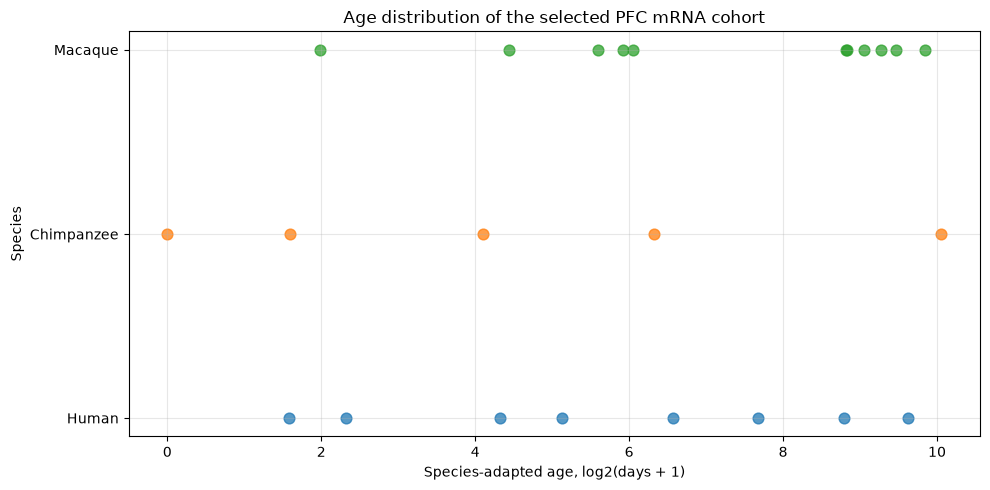

In [5]:
species_order = ["Human", "Chimpanzee", "Macaque"]

plt.figure(figsize=(10, 5))

for species in species_order:
    subset = final_sample_table[
        final_sample_table["Species"] == species
    ]

    plt.scatter(
        subset["Log2_species_adapted_age"],
        [species] * len(subset),
        label=species,
        s=60,
        alpha=0.75
    )

plt.xlabel("Species-adapted age, log2(days + 1)")
plt.ylabel("Species")
plt.title("Age distribution of the selected PFC mRNA cohort")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


6.) Export the human-specific analysis inputs

The gene annotation produced by 1a is unchanged and does not need to be exported again.


In [6]:
mrna_gene_selected.to_csv(
    "data/pfc_mrna_gene_expression_human_spec.csv"
)

final_sample_table.to_csv(
    "data/pfc_mrna_selected_sample_info_human_spec.csv",
    index=False
)

print(
    "Exported data/pfc_mrna_gene_expression_human_spec.csv:",
    mrna_gene_selected.shape
)
print(
    "Exported data/pfc_mrna_selected_sample_info_human_spec.csv:",
    final_sample_table.shape
)


Exported data/pfc_mrna_gene_expression_human_spec.csv: (11667, 24)
Exported data/pfc_mrna_selected_sample_info_human_spec.csv: (24, 6)
